# 04 · Model comparison, tuning and selection

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "carprice").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from carprice.config import load_settings
S = load_settings()
P = S.paths
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
def show_fig(name):
    display(Image(filename=str(P.figures / name), width=900))
def md(text): display(Markdown(text))


## All models: same folds, same preprocessing options
19 candidates × 2 feature sets (baselines once). Metrics are cross-validated on the training split (5 folds × 3 repeats); ± is the standard error over the 15 folds.

In [2]:
t = pd.read_csv(P.metrics / "model_comparison.csv")
cols = ["model","variant","mae_inr","mae_se","rmse_inr","medae_inr","r2","rmsle","mape_pct","mase","fit_s","predict_ms_per_row","model_kb"]
display(t[cols])
md(f"**{t.model.nunique()} distinct models, {len(t)} model×feature-set runs, {int((t.status!='ok').sum())} failures.** Excluded models: `{json.load(open(P.metrics/'excluded_models.json')) or 'none'}`")

,model,variant,mae_inr,mae_se,rmse_inr,medae_inr,r2,rmsle,mape_pct,mase,fit_s,predict_ms_per_row,model_kb
0,huber,base_plus_parsed,"97,341.341","3,517.555","213,892.170","45,219.276",0.623,0.401,30.353,0.427,0.177,0.131,5.100
1,linear,base_plus_parsed,"100,512.559","3,645.144","192,704.680","50,900.839",0.714,0.395,30.589,0.440,0.035,0.144,5.700
2,extra_trees,target_encoded,"101,765.189","3,311.224","187,259.351","52,060.788",0.739,0.387,29.634,0.445,0.328,0.780,"3,488.600"
3,svr,base_plus_parsed,"103,004.952","3,366.831","198,105.903","50,135.933",0.707,0.402,30.686,0.450,0.045,0.168,25.900
4,ebm,base_plus_parsed,"105,321.301","3,373.684","201,388.764","53,662.751",0.701,0.393,31.267,0.459,8.058,0.158,226.600
5,catboost,base_plus_parsed,"105,382.367","3,633.377","198,176.910","53,565.454",0.709,0.393,30.788,0.460,0.402,0.168,102.600
6,catboost,target_encoded,"105,800.514","3,598.702","198,859.282","55,333.148",0.707,0.389,30.218,0.462,0.433,0.158,133.900
7,xgboost,base_plus_parsed,"106,135.181","3,305.063","195,345.114","54,898.180",0.714,0.394,30.528,0.464,0.151,0.159,110.900
8,gradient_boosting,target_encoded,"106,305.555","3,557.492","192,571.778","57,367.155",0.724,0.396,31.253,0.464,0.356,0.176,109.900
9,xgboost,target_encoded,"106,332.046","3,596.259","194,511.287","55,912.439",0.720,0.396,30.871,0.464,0.126,0.162,141.400


**19 distinct models, 36 model×feature-set runs, 0 failures.** Excluded models: `none`

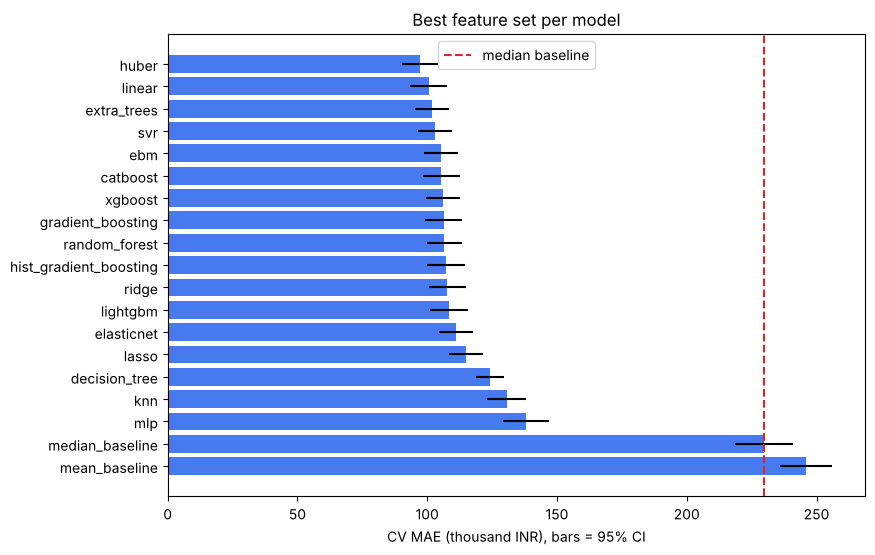

**Reading this:** the top ~12 models sit within about two standard errors of each other. On a ~580-row training set, differences of a few thousand rupees between them are noise, which is exactly why the selection rule below prefers simpler models when scores are tied.

In [3]:
best = t.sort_values("mae_inr").groupby("model").first().sort_values("mae_inr")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(best.index[::-1], best.mae_inr[::-1]/1e3, xerr=1.96*best.mae_se[::-1]/1e3, color="#2563eb", alpha=.85)
ax.axvline(best.loc["median_baseline","mae_inr"]/1e3, color="#dc2626", ls="--", label="median baseline")
ax.set(xlabel="CV MAE (thousand INR), bars = 95% CI", title="Best feature set per model"); ax.legend(); plt.show()
md("**Reading this:** the top ~12 models sit within about two standard errors of each other. On a ~580-row training set, differences of a few thousand rupees between them are noise, "
   "which is exactly why the selection rule below prefers simpler models when scores are tied.")

### Why the MLP is not competitive (and one run is unstable)

In [4]:
display(t[t.model=="mlp"][["model","variant","mae_inr","mae_se","r2","rmsle"]])
md("A neural network is included for completeness. With <1k tabular rows it is not expected to win; "
   "the `base_plus_parsed` run has a huge SE and negative R² because one CV fold produced extreme predictions (heavy-tailed `kms_per_year` input). "
   "It is reported as-is rather than hidden or tuned until it looks good.")

,model,variant,mae_inr,mae_se,r2,rmsle
32,mlp,target_encoded,"138,136.815","4,552.671",0.407,0.446
33,mlp,base_plus_parsed,"153,680.866","23,805.116",-1.952,0.486


A neural network is included for completeness. With <1k tabular rows it is not expected to win; the `base_plus_parsed` run has a huge SE and negative R² because one CV fold produced extreme predictions (heavy-tailed `kms_per_year` input). It is reported as-is rather than hidden or tuned until it looks good.

## Hyper-parameter tuning
GridSearchCV (small linear spaces), RandomizedSearchCV (forests), Optuna/TPE (boosting, SVR). Tuning uses *training* folds that differ from the comparison folds; the test set is never touched. Optuna studies live in a journal file so interrupted runs resume.

In [5]:
tu = pd.read_csv(P.metrics / "tuning_results.csv")
display(tu[["model","variant","method","n_trials","default_mae_inr","mae_inr","mae_gain_pct","search_seconds","fit_s","predict_ms_per_row","model_kb","best_params"]])
md("⚠️ Tuned CV scores are slightly optimistic (the same training data chose the parameters). The untouched test split gives the unbiased number (notebook 05).")

,model,variant,method,n_trials,default_mae_inr,mae_inr,mae_gain_pct,search_seconds,fit_s,predict_ms_per_row,model_kb,best_params
0,svr,base_plus_parsed,optuna,40,"103,004.952","93,435.928",9.290,21.100,0.060,0.185,24.400,"{""C"": 49.9706050271911, ""epsilon"": 0.053037549..."
1,catboost,base_plus_parsed,optuna,40,"105,382.367","100,746.173",4.399,55.400,0.162,0.146,52.000,"{""depth"": 3, ""iterations"": 572, ""l2_leaf_reg"":..."
2,extra_trees,target_encoded,random,30,"101,765.189","101,339.372",0.418,62.600,0.430,0.973,"3,394.100","{""max_depth"": 12, ""max_features"": 1.0, ""min_sa..."
3,catboost,target_encoded,optuna,40,"105,800.514","105,672.719",0.121,82.300,0.404,0.193,119.600,"{""depth"": 5, ""iterations"": 689, ""l2_leaf_reg"":..."


⚠️ Tuned CV scores are slightly optimistic (the same training data chose the parameters). The untouched test split gives the unbiased number (notebook 05).

## Selection (documented rule, not 'highest R²')

In [6]:
md(open(P.model_reports / "model_selection.md").read().split("\n\n", 3)[3] if False else "")
sel = json.load(open(P.metrics / "selection.json"))
md(f"**Selected: `{sel['selected']}`** on `{sel['selected_variant']}` ({'tuned' if sel['selected_tuned'] else 'default'} hyper-parameters).")
md(sel["rationale"])
st = pd.read_csv(P.metrics / "selection_table.csv")
display(st[["model","variant","tuned","mae_inr","mae_se","rmse_inr","r2","tier","model_kb","predict_ms_per_row","eligible"]].head(15))

**Selected: `svr`** on `base_plus_parsed` (tuned hyper-parameters).

Best CV MAE: svr (93,436 INR, SE 3,400). 1 model(s) are statistically tied with it (MAE <= 96,836 and RMSE <= 193,929). Among those the simplest (interpretability tier 4, 24 KB) is 'svr'.

,model,variant,tuned,mae_inr,mae_se,rmse_inr,r2,tier,model_kb,predict_ms_per_row,eligible
0,svr,base_plus_parsed,True,"93,435.928","3,399.822","179,974.708",0.752,4,24.400,0.185,True
1,huber,base_plus_parsed,False,"97,341.341","3,517.555","213,892.170",0.623,1,5.100,0.131,False
2,linear,base_plus_parsed,False,"100,512.559","3,645.144","192,704.680",0.714,1,5.700,0.144,False
3,catboost,base_plus_parsed,True,"100,746.173","3,702.597","189,063.586",0.730,3,52.000,0.146,False
4,extra_trees,target_encoded,True,"101,339.372","3,307.448","186,701.406",0.739,3,"3,394.100",0.973,False
5,extra_trees,target_encoded,False,"101,765.189","3,311.224","187,259.351",0.739,3,"3,488.600",0.780,False
6,svr,base_plus_parsed,False,"103,004.952","3,366.831","198,105.903",0.707,4,25.900,0.168,False
7,ebm,base_plus_parsed,False,"105,321.301","3,373.684","201,388.764",0.701,1,226.600,0.158,False
8,catboost,base_plus_parsed,False,"105,382.367","3,633.377","198,176.910",0.709,3,102.600,0.168,False
9,catboost,target_encoded,True,"105,672.719","3,112.424","195,654.711",0.719,3,119.600,0.193,False


Rule: best CV MAE; every model within one standard error on **MAE and RMSE** is tied; ties are broken by interpretability tier → model size → MAE. Segment performance and stability are then checked on the chosen model in notebook 05.